In [109]:
# What is KNN?

# KNN stands for Closest Nearest Neighbors. It is a type of supervised machine learning. It is used for classification and regression. It predicts the output based on the majority class (classification) or average value (regression) of the k nearest data points.


# Key Concepts:
# 1. Instance Based / Lazy Learning
# - No training phase
# 2. Entire dataset is stored as a graph
# 3. Prediction happens at query time -> slow for large datasets

# 2. Distance Metrics
# a. Euclidean Distance (most common)
# d(p, q) = √∑(pi - qi)^2

In [110]:
# How to choose k value?

# General rule:
# 1. Small k -> noisy, overfits
# 2. Large k -> too smooth, underfits
# 3. Always choose odd k for binary classification

# 4. KNN is distance based -> features must always be scaled (0 - 1), only for minmaxScalar
# Use standardscaler or minmaxscaler


# scaled_value=(actual_value - mean_of_all_values)/standard_deviation_of_all_values

# Advantages:
# 1. No training cost
# 2. Simple
# 3. Works well for small datasets

# Disadvantage:
# 1. Slow
# 2. High Memory Usage
# 3. Sensitive to noises and irrelevant features
# 4. Sensitive to feature scale

#read_data
#split feature and classifier column
#split in training and testing
#scale feature column
#apply model
#predict outcome

In [111]:
import pandas as pd

df=pd.read_csv('data/student_performance_clean.csv')

df.head()

,Unnamed: 0.1,Unnamed: 0,student_id,gender,study_hours,attendance,previous_score,sleep_hours,internet_access,final_score,pass_status
0,0,0,STU0001,Male,0.0,48.7,47.4,7.9,Yes,52.3,0
1,1,1,STU0002,Male,4.1,58.5,77.5,6.4,No,62.5,1
2,2,2,STU0003,Male,3.9,91.1,54.5,4.3,No,61.4,1
3,3,3,STU0004,Female,5.9,64.8,47.5,5.9,No,67.8,1
4,4,4,STU0005,Male,6.1,71.0,77.6,7.1,Yes,77.8,1


In [112]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score
from sklearn.preprocessing import StandardScaler


X=df[['study_hours','attendance']]
Y=df['pass_status']

x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2)

scaler=StandardScaler()

x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)


In [113]:
model=KNeighborsClassifier(n_neighbors=5)

model.fit(x_train_scaled,y_train)



,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [114]:
y_pred=model.predict(x_test_scaled)

accuracy_score(y_pred,y_test)

0.7783505154639175

In [115]:
value=pd.DataFrame(
    {
        "study_hours":[2],
        "attendance":[78]
    }
    )

value_scaled=scaler.transform(value)

predicted=model.predict(value_scaled)

predicted_probability=model.predict_proba(value_scaled)

print(predicted_probability)
print(predicted)

[[1. 0.]]
[0]


In [116]:
df.head()

,Unnamed: 0.1,Unnamed: 0,student_id,gender,study_hours,attendance,previous_score,sleep_hours,internet_access,final_score,pass_status
0,0,0,STU0001,Male,0.0,48.7,47.4,7.9,Yes,52.3,0
1,1,1,STU0002,Male,4.1,58.5,77.5,6.4,No,62.5,1
2,2,2,STU0003,Male,3.9,91.1,54.5,4.3,No,61.4,1
3,3,3,STU0004,Female,5.9,64.8,47.5,5.9,No,67.8,1
4,4,4,STU0005,Male,6.1,71.0,77.6,7.1,Yes,77.8,1


Text(0, 0.5, 'Attendace')

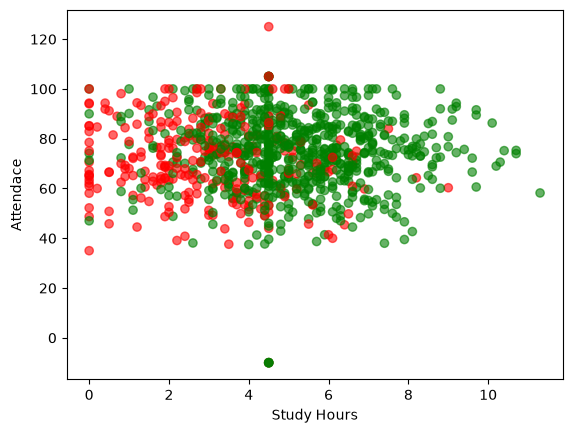

In [117]:
import matplotlib.pyplot as plt

colors=df['pass_status'].map({
    0:"red",
    1:"green"
})

plt.scatter(df['study_hours'],df['attendance'],color=colors,alpha=0.6)
plt.xlabel("Study Hours")
plt.ylabel("Attendace")

In [ ]:
scores=[]
for i in range(1,11,2):
    model_new=KNeighborsClassifier(n_neighbors=i)

    model_new.fit(x_train_scaled,y_train)
    y_prediciton=model_new.predict(x_test)
    score=accuracy_score(y_prediciton,y_test)
    scores.append(score)

i=range(1,11,2)
plt.plot(i,scores)



NameError: name 'model_new' is not defined

In [ ]:
print(scores)

[0.24742268041237114, 0.25773195876288657, 0.25773195876288657, 0.25257731958762886, 0.7525773195876289]
